In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("Book1.csv")

print(df.shape)
print(df.head())
print(df.info())

(1048575, 8)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

        InvoiceDate  Price  Customer ID         Country  
0  01-12-2009 07:45   6.95      13085.0  United Kingdom  
1  01-12-2009 07:45   6.75      13085.0  United Kingdom  
2  01-12-2009 07:45   6.75      13085.0  United Kingdom  
3  01-12-2009 07:45   2.10      13085.0  United Kingdom  
4  01-12-2009 07:45   1.25      13085.0  United Kingdom  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      

# 1. -------- Check Data Quality  -------------

In [3]:

# 1.1 Check column names
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [4]:
# 1.2. Check missing values
print(df.isnull().sum())


Invoice             0
StockCode           0
Description      4372
Quantity            0
InvoiceDate         0
Price               0
Customer ID    236682
Country             0
dtype: int64


In [5]:

# 1.3. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 34150


In [6]:

# 1.4. Check data types
print(df.dtypes)

Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
dtype: object


In [7]:

# 1.5. Check numerical statistics
print(df.describe())

           Quantity         Price    Customer ID
count  1.048575e+06  1.048575e+06  811893.000000
mean   9.957525e+00  4.627346e+00   15324.712265
std    1.335187e+02  1.228024e+02    1697.033034
min   -7.421500e+04 -5.359436e+04   12346.000000
25%    1.000000e+00  1.250000e+00   13971.000000
50%    3.000000e+00  2.100000e+00   15260.000000
75%    1.000000e+01  4.150000e+00   16795.000000
max    7.421500e+04  3.897000e+04   18287.000000


In [8]:

# 1.6. Check unique values in each column
print(df.nunique())

Invoice        52961
StockCode       5304
Description     5692
Quantity        1048
InvoiceDate    47046
Price           2784
Customer ID     5924
Country           43
dtype: int64


# 1.2 Handling Missing Values

In [10]:
# --------- Handling missing values-------------
print(df[["Description", "Customer ID"]].isnull().sum())

Description      4372
Customer ID    236682
dtype: int64


In [11]:
# Handling missing description
missing_desc = df[df["Description"].isnull()]

print("Missing descriptions:", len(missing_desc))
print(missing_desc[["StockCode", "Quantity", "Price"]].head(10))

Missing descriptions: 4372
     StockCode  Quantity  Price
470      21646       -50    0.0
3114     20683       -44    0.0
3161     21350       230    0.0
3731     84292        17    0.0
4296     18010      -770    0.0
4566    85049G      -240    0.0
6378    35751C        12    0.0
6555    79323G       954    0.0
6576     21098      -200    0.0
6581     21166        48    0.0


In [12]:
df["Description"] = df["Description"].fillna("Unknown Product")

In [13]:
# Handle missing Customer ID
print("Missing Customer IDs:", df["Customer ID"].isnull().sum())
print("Missing percentage:",
      round(df["Customer ID"].isnull().mean() * 100, 2), "%")

Missing Customer IDs: 236682
Missing percentage: 22.57 %


In [14]:
df["Customer ID"] = df["Customer ID"].astype("string")
df["Customer ID"] = df["Customer ID"].fillna("Unknown")

In [15]:
print(df[["Description", "Customer ID"]].isnull().sum())
print("Final shape:", df.shape)

Description    0
Customer ID    0
dtype: int64
Final shape: (1048575, 8)


 # 1.2 Handling duplicates

In [17]:
print("Total rows:", len(df))
print("Exact duplicate rows to investigate:", df.duplicated().sum())

Total rows: 1048575
Exact duplicate rows to investigate: 34150


In [18]:
exact_duplicates = df[df.duplicated(keep=False)]

print(exact_duplicates.head(20))

    Invoice StockCode                        Description  Quantity  \
362  489517     21913     VINTAGE SEASIDE JIGSAW PUZZLES         1   
363  489517     21912           VINTAGE SNAKES & LADDERS         1   
365  489517     21821   GLITTER STAR GARLAND WITH BELLS          1   
367  489517     22319  HAIRCLIPS FORTIES FABRIC ASSORTED        12   
368  489517     22130   PARTY CONE CHRISTMAS DECORATION          6   
371  489517     21912           VINTAGE SNAKES & LADDERS         1   
379  489517     21491    SET OF THREE VINTAGE GIFT WRAPS         1   
383  489517     22130   PARTY CONE CHRISTMAS DECORATION          6   
384  489517     22319  HAIRCLIPS FORTIES FABRIC ASSORTED        12   
385  489517     21913     VINTAGE SEASIDE JIGSAW PUZZLES         1   
386  489517     21821   GLITTER STAR GARLAND WITH BELLS          1   
388  489517    84951A    S/4 PISTACHIO LOVEBIRD COASTERS         1   
390  489517    84951A    S/4 PISTACHIO LOVEBIRD COASTERS         1   
391  489517     2149

In [19]:
# Cross checking things
# Check whether row 362 has an exact matching row
df[df.eq(df.iloc[362]).all(axis=1)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,01-12-2009 11:34,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,01-12-2009 11:34,3.75,16329.0,United Kingdom


In [20]:
# Check whether row 363 has an exact matching row
df[df.eq(df.iloc[363]).all(axis=1)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
363,489517,21912,VINTAGE SNAKES & LADDERS,1,01-12-2009 11:34,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,01-12-2009 11:34,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,01-12-2009 11:34,3.75,16329.0,United Kingdom


In [21]:
# Count how many times each complete row appears
duplicate_counts = (
    df.value_counts()
      .reset_index(name="Count")
)

# Show rows that appear more than once
duplicate_counts[duplicate_counts["Count"] > 1].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Count
0,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,05-06-2011 11:37,2.95,16923.0,United Kingdom,20
1,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,05-06-2011 11:37,2.95,16923.0,United Kingdom,12
2,537224,70007,HI TEC ALPINE HAND WARMER,1,05-12-2010 16:24,1.65,13174.0,United Kingdom,10
3,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,26-10-2011 12:46,1.25,14102.0,United Kingdom,8
4,537196,21811,CHRISTMAS HANGING HEART WITH BELL,1,05-12-2010 13:55,1.25,15426.0,United Kingdom,6
5,572344,M,Manual,48,24-10-2011 10:43,1.50,14607.0,United Kingdom,6
6,536796,21967,PACK OF 12 SKULL TISSUES,1,02-12-2010 15:46,0.29,15574.0,United Kingdom,6
7,537208,90082B,DIAMANTE BOW BROOCH RED COLOUR,1,05-12-2010 15:12,6.35,15889.0,United Kingdom,6
8,537042,21579,LOLITA DESIGN COTTON TOTE BAG,1,05-12-2010 10:45,2.25,13838.0,United Kingdom,6
9,537265,79000,MOROCCAN TEA GLASS,12,06-12-2010 11:26,0.85,15919.0,United Kingdom,6


In [22]:
# Deleting exactly same rows as they are duplicate
print("Original shape: ",df.shape)
df = df.drop_duplicates()

print("After removing duplicate , current shape : ",df.shape)

Original shape:  (1048575, 8)
After removing duplicate , current shape :  (1014425, 8)


# 1.3 Changing data type

In [44]:
# Only of invoice
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%d-%m-%Y %H:%M"
)

In [46]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID    string[python]
Country                object
dtype: object

# 1.4 Handling negative and zero values

In [50]:
# Quantity and price
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())

print("Negative Price:", (df["Price"] < 0).sum())
print("Zero Price:", (df["Price"] == 0).sum())

Negative Quantity: 22244
Zero Quantity: 0
Negative Price: 5
Zero Price: 5978


In [52]:
df[df["Price"] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,Unknown,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,Unknown,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,Unknown,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,Unknown,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,Unknown,United Kingdom


In [54]:
df = df[df["Price"] >= 0].copy()

# 1.5  Sales 

In [56]:
df["Sales"] = df["Quantity"] * df["Price"]

In [58]:
df[["Quantity", "Price", "Sales"]].head(10)

,Quantity,Price,Sales
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0
5,24,1.65,39.6
6,24,1.25,30.0
7,10,5.95,59.5
8,12,2.55,30.6
9,12,3.75,45.0


# 1.6 Extract Month and Year

In [64]:
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)

In [66]:
df[["InvoiceDate", "Year", "Month", "YearMonth"]].head()

,InvoiceDate,Year,Month,YearMonth
0,2009-12-01 07:45:00,2009,12,2009-12
1,2009-12-01 07:45:00,2009,12,2009-12
2,2009-12-01 07:45:00,2009,12,2009-12
3,2009-12-01 07:45:00,2009,12,2009-12
4,2009-12-01 07:45:00,2009,12,2009-12


# Return and cancellation orders

In [69]:
print("Cancelled invoices:", 
      df["Invoice"].astype(str).str.startswith("C").sum())

print("Negative quantity rows:", 
      (df["Quantity"] < 0).sum())

Cancelled invoices: 18872
Negative quantity rows: 22244


In [71]:
print("Negative Quantity with C invoice:",
      ((df["Quantity"] < 0) &
       df["Invoice"].astype(str).str.startswith("C")).sum())

print("Negative Quantity without C invoice:",
      ((df["Quantity"] < 0) &
       ~df["Invoice"].astype(str).str.startswith("C")).sum())

Negative Quantity with C invoice: 18871
Negative Quantity without C invoice: 3373


In [73]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
Sales          0
Year           0
Month          0
YearMonth      0
dtype: int64

In [75]:
print("Dataset shape:", df.shape)

print("Exact duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nBasic statistics:")
display(df.describe())

Dataset shape: (1014420, 12)
Exact duplicate rows: 0

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID    string[python]
Country                object
Sales                 float64
Year                    int32
Month                   int32
YearMonth              object
dtype: object

Basic statistics:


,Quantity,InvoiceDate,Price,Sales,Year,Month
count,1.014420e+06,1014420,1.014420e+06,1.014420e+06,1.014420e+06,1.014420e+06
mean,1.009730e+01,2010-12-28 09:54:57.134381312,4.746558e+00,1.843419e+01,2.010425e+03,7.308853e+00
min,-7.421500e+04,2009-12-01 07:45:00,0.000000e+00,-7.718360e+04,2.009000e+03,1.000000e+00
25%,1.000000e+00,2010-06-30 15:34:00,1.250000e+00,3.750000e+00,2.010000e+03,4.000000e+00
50%,3.000000e+00,2010-12-06 10:08:00,2.100000e+00,9.950000e+00,2.010000e+03,8.000000e+00
75%,1.000000e+01,2011-07-17 13:32:00,4.150000e+00,1.770000e+01,2.011000e+03,1.000000e+01
max,7.421500e+04,2011-12-04 13:15:00,3.897000e+04,7.718360e+04,2.011000e+03,1.200000e+01
std,1.352803e+02,NaN,9.112027e+01,1.613345e+02,5.766949e-01,3.476364e+00


# -------------   EDA  --------------------

In [78]:
print("Total Sales:", df["Sales"].sum())
print("Total Transactions:", df["Invoice"].nunique())
print("Unique Products:", df["StockCode"].nunique())
print("Unique Customers:", df["Customer ID"].nunique())
print("Countries:", df["Country"].nunique())

Total Sales: 18700009.827999998
Total Transactions: 52956
Unique Products: 5304
Unique Customers: 5925
Countries: 43


In [80]:
monthly_sales = (
    df.groupby("YearMonth")["Sales"]
      .sum()
      .reset_index()
      .sort_values("YearMonth")
)

display(monthly_sales)

,YearMonth,Sales
0,2009-12,796648.500
1,2010-01,622479.502
2,2010-02,531265.366
3,2010-03,763247.241
4,2010-04,641521.052
5,2010-05,613270.720
6,2010-06,677073.870
7,2010-07,617365.480
8,2010-08,654774.390
9,2010-09,851105.961


In [82]:
monthly_sales.nlargest(5, "Sales")

,YearMonth,Sales
23,2011-11,1456145.800
11,2010-11,1416697.202
10,2010-10,1080611.480
22,2011-10,1069368.230
21,2011-09,1017596.682


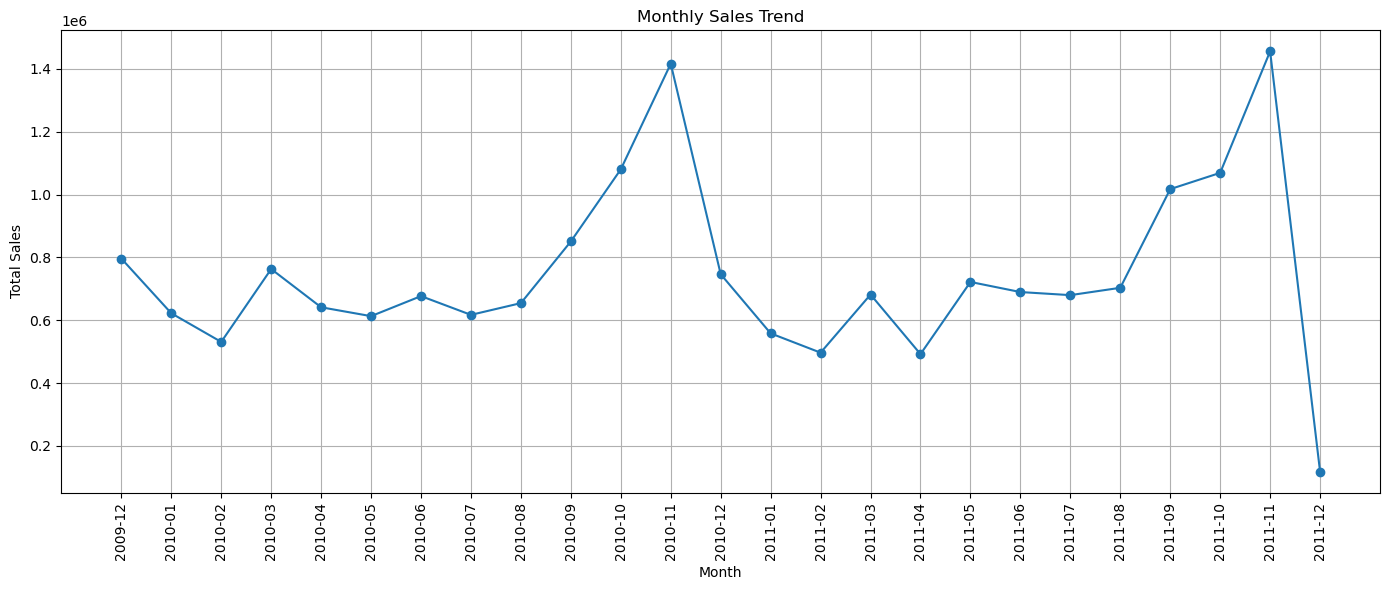

In [84]:
import matplotlib.pyplot as plt

monthly_sales = monthly_sales.sort_values("YearMonth")

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_sales["YearMonth"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [86]:
top_products = (
    df.groupby("Description")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

display(top_products)

,Description,Sales
0,REGENCY CAKESTAND 3 TIER,308887.27
1,DOTCOM POSTAGE,292176.56
2,WHITE HANGING HEART T-LIGHT HOLDER,249847.18
3,PARTY BUNTING,146492.79
4,JUMBO BAG RED RETROSPOT,144948.88
5,ASSORTED COLOUR BIRD ORNAMENT,127378.96
6,PAPER CHAIN KIT 50'S CHRISTMAS,111078.75
7,POSTAGE,108308.62
8,CHILLI LIGHTS,78196.62
9,ROTATING SILVER ANGELS T-LIGHT HLDR,69011.26


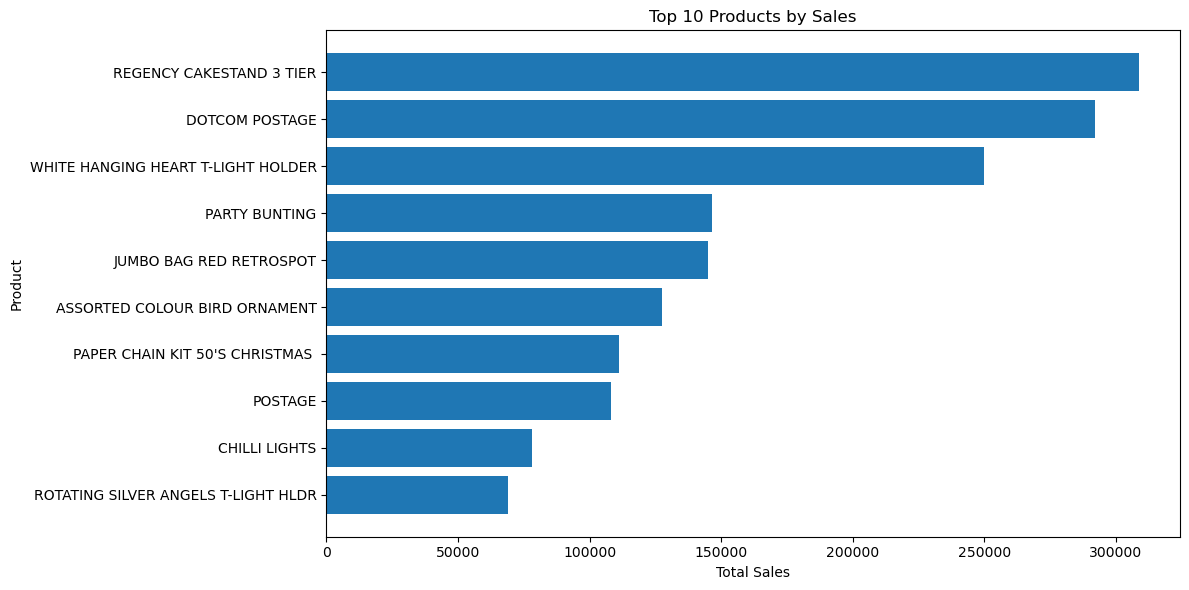

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["Description"][::-1],
    top_products["Sales"][::-1]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [90]:
df.to_csv("online_retail_cleaned.csv", index=False)